In [1]:
import torch
import cv2
import os
import matplotlib.pyplot as plt
from stdev.utils.image_tools import *
from rqi import RQI

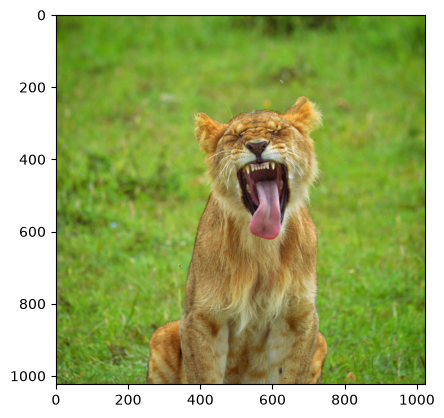

In [2]:
image = cv2.imread("../datasets/axis-v1_1k/Animals_Photo/animals_001.jpg")
image = crop_maximal_rectangle(image, target_height=1024, target_width=1024)
cv2.imwrite("samples/img.png", image)
image = cv2_to_np(image)

plt.imshow(image)

In [3]:
rqi = RQI()

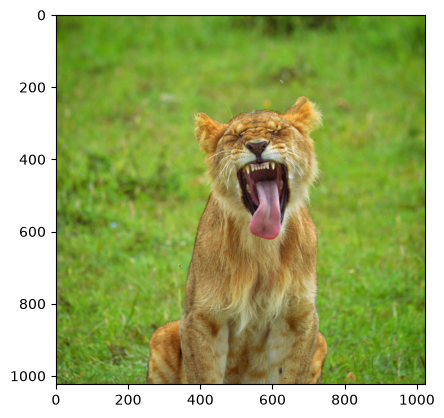

0.5322102904319763


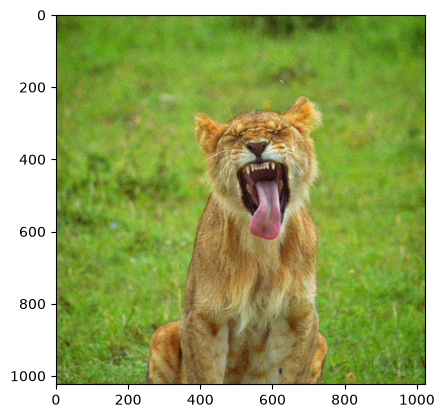

0.5033120512962341


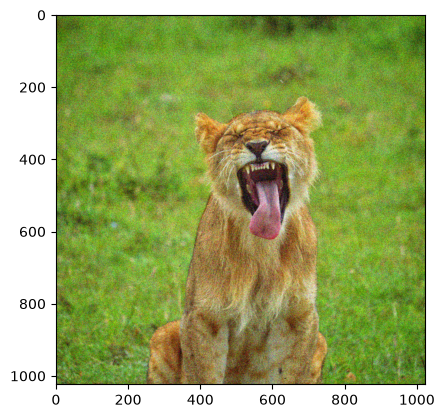

0.44393888115882874


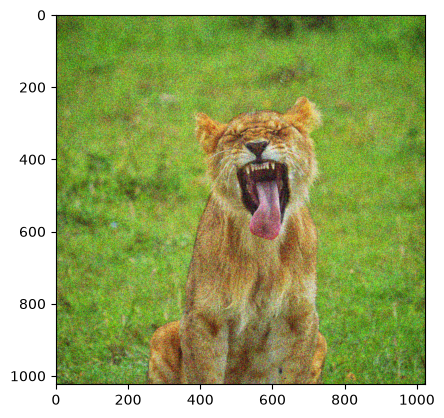

0.4287329912185669


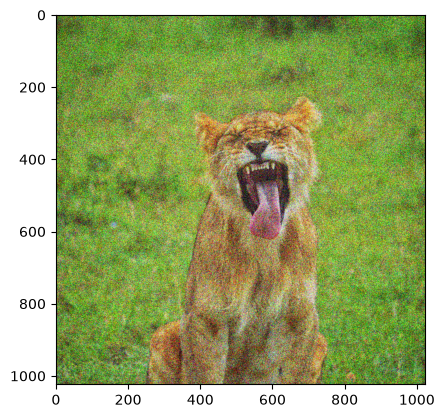

0.419448584318161


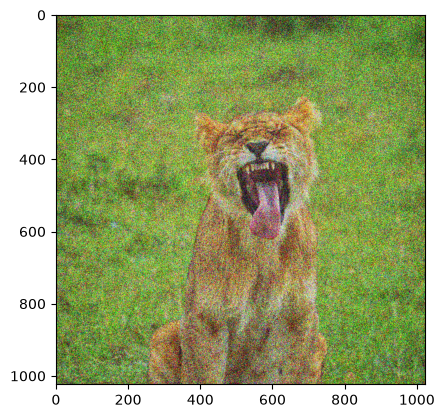

0.40193015336990356


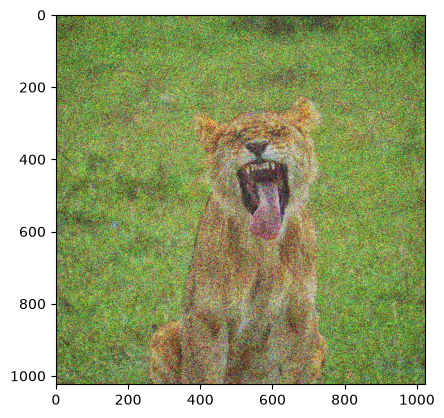

0.3757464289665222


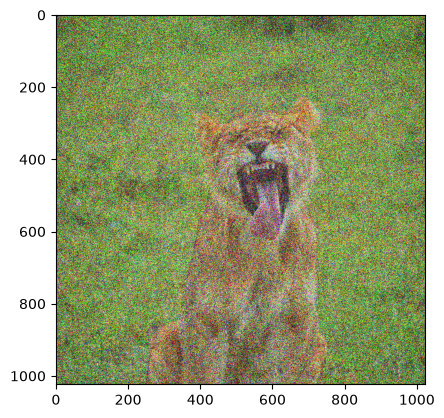

0.3950928747653961


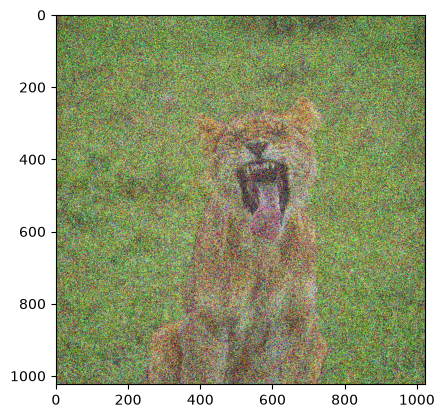

0.3848988115787506


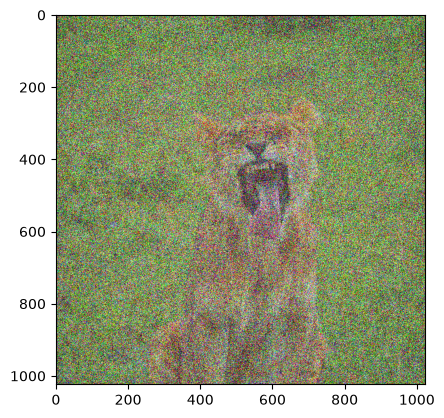

0.38004234433174133


In [4]:
for i in range(0, 300, 30):
    image_n = image + np.random.uniform(-i, i, size=image.shape)
    image_n = np.clip(image_n, 0, 255)
    image_n = image_n.astype(np.uint8)
    plt.imshow(image_n)
    plt.show()

    score = rqi(image_n, image)
    print(score)

In [6]:
import torch
from stdev.vaes.flux_2_vae import Flux2VAE

device = "cuda" if torch.cuda.is_available() else "cpu"

vae = Flux2VAE(path_to_model="../models/FLUX.2-klein-4B/vae", device=device)


The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.
There are modules in AutoencoderKLFlux2 that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


tensor(0.0003, device='cuda:0')


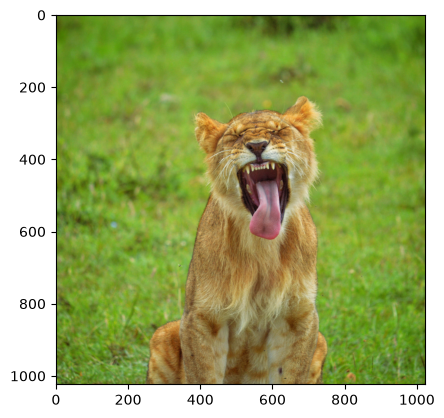

In [7]:
i = np_to_torch(image)
l = vae.encode(i)
rec = vae.decode(l)

plt.imshow(torch_to_np(rec))
print(((rec - i) ** 2).mean())

tensor(0.0003, device='cuda:0')


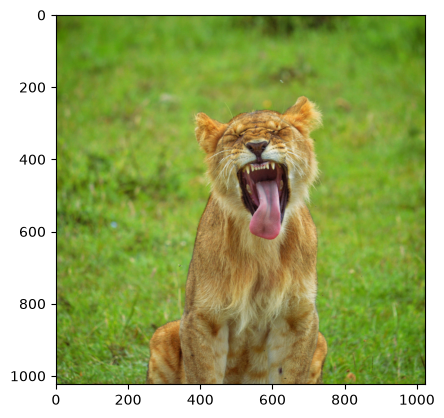

In [8]:
import vaezip


i = np_to_torch(image)
l = vae.encode(i)
vaezip.save_tensor(l, "samples/latents.vz.safetensors", codec="lbrq_6bit")

l = vaezip.load_tensor("samples/latents.vz.safetensors", device=device)
rec = vae.decode(l)

plt.imshow(torch_to_np(rec))
print(((rec - i) ** 2).mean())

USDT:2026-10-25 13:26:53 3490:3490 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-25 13:26:53 3490:3490 SyncActivityProfilerHandler.cpp:46] profiler_stop


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                  cudaDeviceSynchronize        98.56%     194.498ms        98.56%     194.498ms     194.498ms       0.000us         0.00%       0.000us       0.000us           0 B           0 B           0 B           0 

/tmp/ipykernel_3490/2724818420.py:36: FutureWarning: `export_memory_timeline` is deprecated and will be removed in a future version. Please use `torch.cuda.memory._record_memory_history` and `torch.cuda.memory._export_memory_snapshot` instead.
  prof.export_memory_timeline("samples/memory_timeline.html")


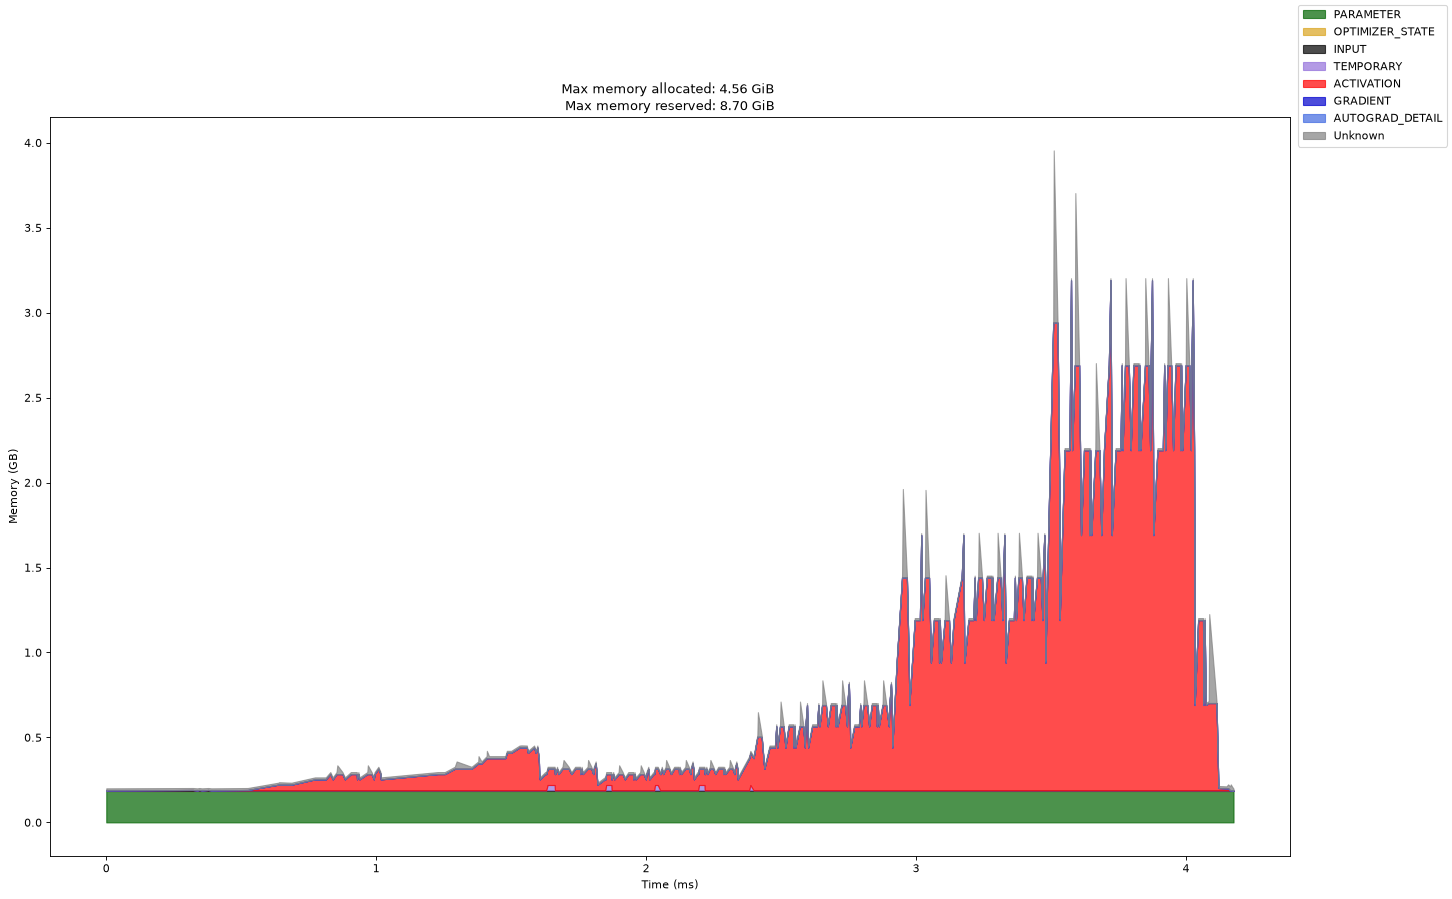

In [38]:
import torch

for i in range(10):
    with torch.no_grad():
        rec = vae.decode(l)
        torch.cuda.synchronize()

with torch.profiler.profile(
    activities=[
        torch.profiler.ProfilerActivity.CPU,
        torch.profiler.ProfilerActivity.CUDA,
    ],
    profile_memory=True,
    record_shapes=True,
    with_stack=True,
) as prof:
    with torch.no_grad():
        rec = vae.decode(l)

print(
    prof.key_averages().table(
        sort_by="self_cpu_time_total",
        row_limit=20,
    )
)

print(
    prof.key_averages().table(
        sort_by="self_cuda_time_total",
        row_limit=20,
    )
)

prof.export_chrome_trace("samples/trace.json")

prof.export_memory_timeline("samples/memory_timeline.html")

import re
import base64

with open("samples/memory_timeline.html", "r", encoding="utf-8") as f:
    html = f.read()

match = re.search(r'<img[^>]+src=["\']data:image/png;base64,([^"\']+)["\']', html, re.IGNORECASE)

image_data = base64.b64decode(match.group(1))

with open("samples/timeline.png", "wb") as f:
    f.write(image_data)


In [26]:
import torch

torch.cuda.memory._record_memory_history(
    enabled="all",
    context="all",
    stacks="all",
    max_entries=100_000,
)

try:
    with torch.no_grad():
        rec = vae.decode(l)

finally:
    torch.cuda.memory._dump_snapshot("memory_snapshot.pickle")
    torch.cuda.memory._record_memory_history(enabled=None)

In [27]:
!python -m torch.cuda._memory_viz trace_plot memory_snapshot.pickle -o memory_timeline.html

<frozen runpy>:128: RuntimeWarning: 'torch.cuda._memory_viz' found in sys.modules after import of package 'torch.cuda', but prior to execution of 'torch.cuda._memory_viz'; this may result in unpredictable behaviour
